# 02 · Ojala & Garriga (2010) permutation tests on all datasets

**Reference.** M. Ojala and G. C. Garriga, "Permutation tests for studying classifier performance," *J. Mach. Learn. Res.*, vol. 11, pp. 1833–1863, 2010.

Ojala and Garriga ask two different questions about a classifier's cross-validated error:

| Test | Null hypothesis | Permutation | A small p-value means… |
|---|---|---|---|
| **Test 1** | features and label are independent | shuffle the labels | the classifier found real class structure (there is learnable signal) |
| **Test 2** | within each class, features are mutually independent | shuffle each feature separately *inside each class* | the classifier exploits **dependencies between features** (e.g. interactions) |

Test 1 is exactly the model-based signal test of this project. Test 2 adds a diagnostic the rest of the study does not have: it tells us whether the detected signal lives in single features or in their combination.

**Design (mirrors the original paper, scaled to the compute budget):**

* Classifiers: decision tree, Gaussian naive Bayes, 1-nearest neighbour, RBF support vector machine (the paper's classifier families).
* Error: 10-fold stratified cross-validation, same folds for original and permuted data.
* k = 200 permutations per test (the paper used 1,000; with k = 200 the smallest attainable p-value is 1/201 ≈ 0.005).
* Datasets with signal: Adult, Pima, Banknote, Breast Cancer, a synthetic **linear** dataset and a synthetic **interaction-only** dataset.
* Datasets without signal: the NSW randomised experiment (pre-treatment covariates → treatment assignment), the Malawi randomised incentive experiment (individual covariates only), and Adult with randomly permuted labels.
* An instructive extra case: the incentive experiment **including village**, where assignment rates differed by village (see notebook 00), so the target does depend on a feature.

Adult is run on a stratified random subsample of 2,000 rows because the SVM and 1-NN costs grow quickly with n; the subsample still contains strong signal.

In [1]:
import json
def load_library_source(path="01_probe_library.ipynb"):
    """Concatenate the code cells of the library notebook so they can be executed here."""
    nb = json.load(open(path, encoding="utf-8"))
    return "\n\n".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code")

_LIBRARY_IMPORT = True          # tells the library to skip its self-tests
exec(compile(load_library_source(), "probe_library", "exec"))

## 1. Assemble the datasets

In [2]:
rng = np.random.default_rng(GLOBAL_SEED)
adult_full = from_dataframe(load_processed("adult"), "adult")
adult_2k = subsample(adult_full, 2000, rng)
adult_perm = TabularData("adult_permuted_labels", adult_2k.X, rng.permutation(adult_2k.y), adult_2k.Xf,
                         adult_2k.discrete, adult_2k.feature_names, adult_2k.meta)

datasets = {
    "Adult (n=2000)": (adult_2k, "signal"),
    "Pima": (from_dataframe(load_processed("pima"), "pima"), "signal"),
    "Banknote": (from_dataframe(load_processed("banknote"), "banknote"), "signal"),
    "Breast cancer": (from_dataframe(load_processed("breast_cancer"), "breast_cancer"), "signal"),
    "Synthetic linear": (make_synthetic("linear", 1000, 0.80, n_noise=5, seed=11), "signal"),
    "Synthetic interaction": (make_synthetic("interaction", 1000, 0.80, n_noise=5, seed=12), "signal"),
    "NSW (randomised)": (from_dataframe(load_processed("nsw_null"), "nsw_null"), "no signal"),
    "Thornton (randomised)": (from_dataframe(load_processed("thornton_null"), "thornton_null"), "no signal"),
    "Thornton incl. village": (from_dataframe(load_processed("thornton_village"), "thornton_village"), "village-dependent assignment"),
    "Adult, permuted labels": (adult_perm, "no signal"),
}
pd.DataFrame([{"dataset": k, "role": r, "rows": d.n, "model-matrix columns": d.X.shape[1],
               "positive rate": round(d.y.mean(), 3)} for k, (d, r) in datasets.items()])

,dataset,role,rows,model-matrix columns,positive rate
0,Adult (n=2000),signal,2000,105,0.240
1,Pima,signal,768,8,0.349
2,Banknote,signal,1372,4,0.445
3,Breast cancer,signal,569,30,0.627
4,Synthetic linear,signal,1000,10,0.508
5,Synthetic interaction,signal,1000,10,0.509
6,NSW (randomised),no signal,445,8,0.416
7,Thornton (randomised),no signal,2901,3,0.766
8,Thornton incl. village,village-dependent assignment,2901,122,0.766
9,"Adult, permuted labels",no signal,2000,105,0.240


## 2. Run Test 1 and Test 2 for every dataset × classifier

Jobs run in parallel on two processes. Results are cached in `results/ojala_garriga.csv`; only (dataset, classifier) pairs missing from the cache are computed, so delete the file to recompute everything.

In [3]:
CLASSIFIERS = ["decision_tree", "naive_bayes", "1nn", "svm_rbf"]
K_PERM = 200
cache = os.path.join(RESULTS_DIR, "ojala_garriga.csv")

def _job(name, role, data, clf):
    t0 = time.perf_counter()
    r = ojala_garriga_tests(clf, data.X, data.y, k=K_PERM, n_folds=10, seed=7, groups=data.meta.get("groups"))
    r.update({"dataset": name, "role": role, "seconds": time.perf_counter() - t0})
    return r

og = pd.read_csv(cache) if os.path.exists(cache) else pd.DataFrame(columns=["dataset", "classifier"])
done = set(zip(og.dataset, og.classifier))
jobs = [(n, r, d, c) for n, (d, r) in datasets.items() for c in CLASSIFIERS if (n, c) not in done]
if jobs:
    new = pd.DataFrame(Parallel(n_jobs=2)(delayed(_job)(*j) for j in jobs))
    og = pd.concat([og, new], ignore_index=True) if len(og) else new
    og.to_csv(cache, index=False)
og = og[og.dataset.isin(list(datasets))]
print(f"total compute: {og.seconds.sum()/60:.1f} CPU-minutes")

total compute: 133.0 CPU-minutes


## 3. Results

In [4]:
tbl = og.assign(accuracy=1 - og.error)[["dataset", "role", "classifier", "accuracy", "p_test1", "p_test2",
                                         "mean_error_test1", "mean_error_test2"]]
tbl["Test 1 significant"] = tbl.p_test1 <= ALPHA
tbl["Test 2 significant"] = tbl.p_test2 <= ALPHA
tbl.round(3)

,dataset,role,classifier,accuracy,p_test1,p_test2,mean_error_test1,mean_error_test2,Test 1 significant,Test 2 significant
0,Adult (n=2000),signal,decision_tree,0.814,0.005,1.000,0.373,0.146,True,False
1,Adult (n=2000),signal,naive_bayes,0.328,0.005,1.000,0.743,0.659,True,False
2,Adult (n=2000),signal,1nn,0.786,0.005,1.000,0.365,0.161,True,False
3,Adult (n=2000),signal,svm_rbf,0.846,0.005,1.000,0.240,0.089,True,False
4,Pima,signal,decision_tree,0.702,0.005,0.920,0.461,0.275,True,False
5,Pima,signal,naive_bayes,0.758,0.005,1.000,0.372,0.218,True,False
6,Pima,signal,1nn,0.711,0.005,0.846,0.455,0.274,True,False
7,Pima,signal,svm_rbf,0.763,0.005,1.000,0.353,0.199,True,False
8,Banknote,signal,decision_tree,0.985,0.005,0.005,0.495,0.135,True,True
9,Banknote,signal,naive_bayes,0.838,0.005,1.000,0.456,0.126,True,False


In [5]:
summary = (tbl.groupby(["dataset", "role"], sort=False)
              .agg(classifiers_test1_sig=("Test 1 significant", "sum"),
                   classifiers_test2_sig=("Test 2 significant", "sum"),
                   best_accuracy=("accuracy", "max"))
              .reset_index())
summary["n_classifiers"] = len(CLASSIFIERS)
summary

,dataset,role,classifiers_test1_sig,classifiers_test2_sig,best_accuracy,n_classifiers
0,Adult (n=2000),signal,4,0,0.846500,4
1,Pima,signal,4,0,0.763021,4
2,Banknote,signal,4,3,1.000000,4
3,Breast cancer,signal,4,0,0.975395,4
4,Synthetic linear,signal,4,0,0.698000,4
5,Synthetic interaction,signal,2,2,0.644000,4
6,NSW (randomised),no signal,0,0,0.595506,4
7,"Adult, permuted labels",no signal,0,0,0.760500,4
8,Thornton incl. village,village-dependent assignment,3,0,0.764219,4
9,Thornton (randomised),no signal,0,0,0.765943,4


### Visual summary

Each panel shows −log10(p) per classifier. The dashed line marks p = 0.05; bars above it are significant. The ceiling is −log10(1/201) ≈ 2.3, the smallest p-value attainable with 200 permutations.

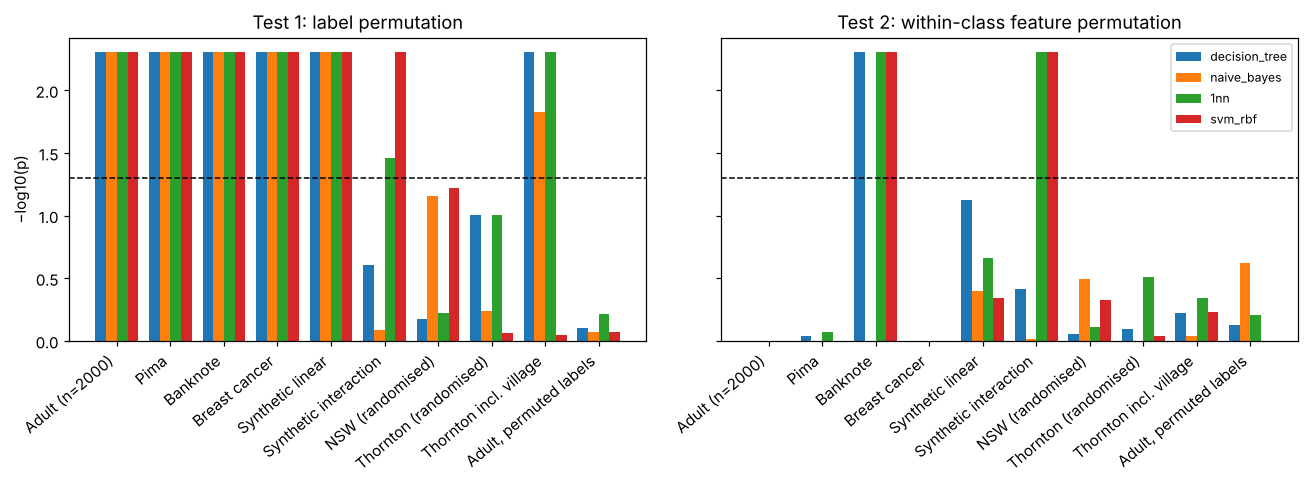

In [6]:
import matplotlib.pyplot as plt
names = list(datasets)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
width = 0.2
for ax, col, title in [(axes[0], "p_test1", "Test 1: label permutation"),
                       (axes[1], "p_test2", "Test 2: within-class feature permutation")]:
    for i, clf in enumerate(CLASSIFIERS):
        vals = [-np.log10(tbl[(tbl.dataset == n) & (tbl.classifier == clf)][col].iloc[0]) for n in names]
        ax.bar(np.arange(len(names)) + (i - 1.5) * width, vals, width, label=clf)
    ax.axhline(-np.log10(ALPHA), ls="--", color="k", lw=1)
    ax.set_xticks(np.arange(len(names)))
    ax.set_xticklabels(names, rotation=40, ha="right")
    ax.set_title(title)
axes[0].set_ylabel("−log10(p)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ojala_garriga.png"), dpi=200, bbox_inches="tight")
plt.show()

## 4. Interpretation

The cells below print the facts that the paper's discussion relies on, computed from the table above rather than typed by hand.

In [7]:
for name in names:
    s = tbl[tbl.dataset == name]
    print(f"{name:24s} Test 1 significant for {int(s['Test 1 significant'].sum())}/4 classifiers; "
          f"Test 2 significant for {int(s['Test 2 significant'].sum())}/4; "
          f"accuracy range {s.accuracy.min():.3f}–{s.accuracy.max():.3f}")

Adult (n=2000)           Test 1 significant for 4/4 classifiers; Test 2 significant for 0/4; accuracy range 0.328–0.847
Pima                     Test 1 significant for 4/4 classifiers; Test 2 significant for 0/4; accuracy range 0.702–0.763
Banknote                 Test 1 significant for 4/4 classifiers; Test 2 significant for 3/4; accuracy range 0.838–1.000
Breast cancer            Test 1 significant for 4/4 classifiers; Test 2 significant for 0/4; accuracy range 0.924–0.975
Synthetic linear         Test 1 significant for 4/4 classifiers; Test 2 significant for 0/4; accuracy range 0.601–0.698
Synthetic interaction    Test 1 significant for 2/4 classifiers; Test 2 significant for 2/4; accuracy range 0.478–0.644
NSW (randomised)         Test 1 significant for 0/4 classifiers; Test 2 significant for 0/4; accuracy range 0.508–0.596
Thornton (randomised)    Test 1 significant for 0/4 classifiers; Test 2 significant for 0/4; accuracy range 0.647–0.766
Thornton incl. village   Test 1 signific